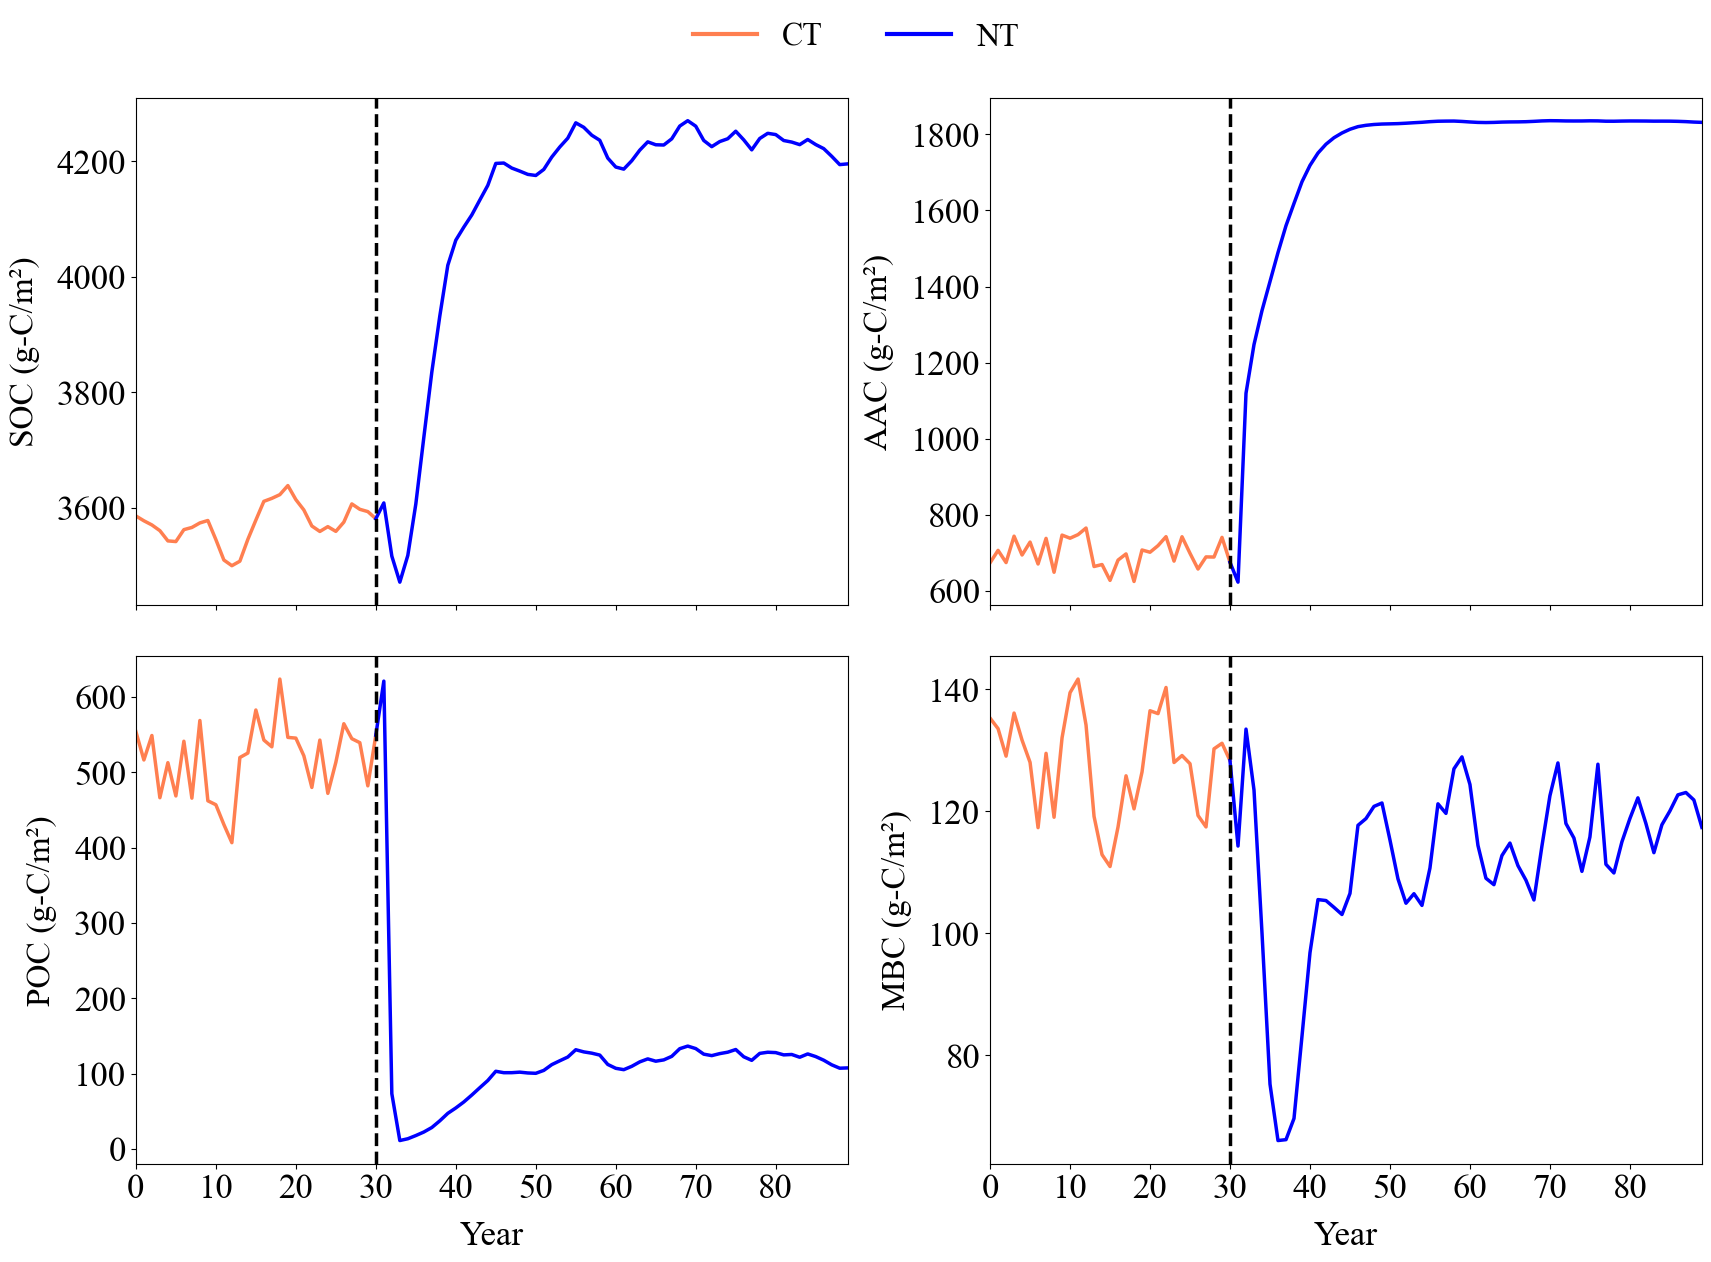

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

mpl.rcParams['font.family'] = 'Times New Roman'
mpl.rcParams['mathtext.fontset'] = 'stix'

START_YEAR = 570
END_YEAR = 659
TRANSITION_YEAR = 600

CT_COLOR = 'coral'
NT_COLOR = 'blue'

data = pd.read_csv('AF_Test_Zr.csv')
data['Years'] = pd.to_numeric(data['Years'])
data = data.sort_values('Years').reset_index(drop=True)

# Calculate total SOC
data['SOC'] = data[['A', 'P', 'DOC', 'M', 'B']].sum(axis=1)

plot_data = data[data['Years'].between(START_YEAR, END_YEAR)].copy()
ct_data = plot_data[plot_data['Years'] <= TRANSITION_YEAR].copy()
nt_data = plot_data[plot_data['Years'] >= TRANSITION_YEAR].copy()

variables = ['SOC', 'A', 'P', 'B']
display_names = ['SOC', 'AAC', 'POC', 'MBC']

fig, axes = plt.subplots(2, 2, figsize=(18, 13), sharex=True)
axes = axes.flatten()

for i, (var, name) in enumerate(zip(variables, display_names)):

    ax = axes[i]

    ax.plot(ct_data['Years'], ct_data[var], color=CT_COLOR, linewidth=2.5, label='CT')
    ax.plot(nt_data['Years'], nt_data[var], color=NT_COLOR, linewidth=2.5, label='NT')
    ax.axvline(x=TRANSITION_YEAR, color='black', linestyle='--', linewidth=2.5)
    ax.set_ylabel(f'{name} (g-C/m²)', fontsize=24, labelpad=12)
    ax.set_xlim(START_YEAR, END_YEAR)
    x_ticks = np.arange(570, 660, 10)
    ax.set_xticks(x_ticks)
    ax.set_xticklabels(x_ticks - START_YEAR)
    ax.tick_params(axis='both', which='major', labelsize=25)
    ax.grid(False)

axes[2].set_xlabel('Year', fontsize=25, labelpad=12)
axes[3].set_xlabel('Year', fontsize=25, labelpad=12)

handles = [plt.Line2D([0], [0], color=CT_COLOR, lw=3, label='CT'), plt.Line2D([0], [0], color=NT_COLOR, lw=3, label='NT')]

fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.99), ncol=2, fontsize=23, frameon=False)
plt.subplots_adjust(left=0.10, right=0.97, bottom=0.09, top=0.91, wspace=0.2, hspace=0.1)
plt.show()